Data loaded******
Plot Data Done. ******


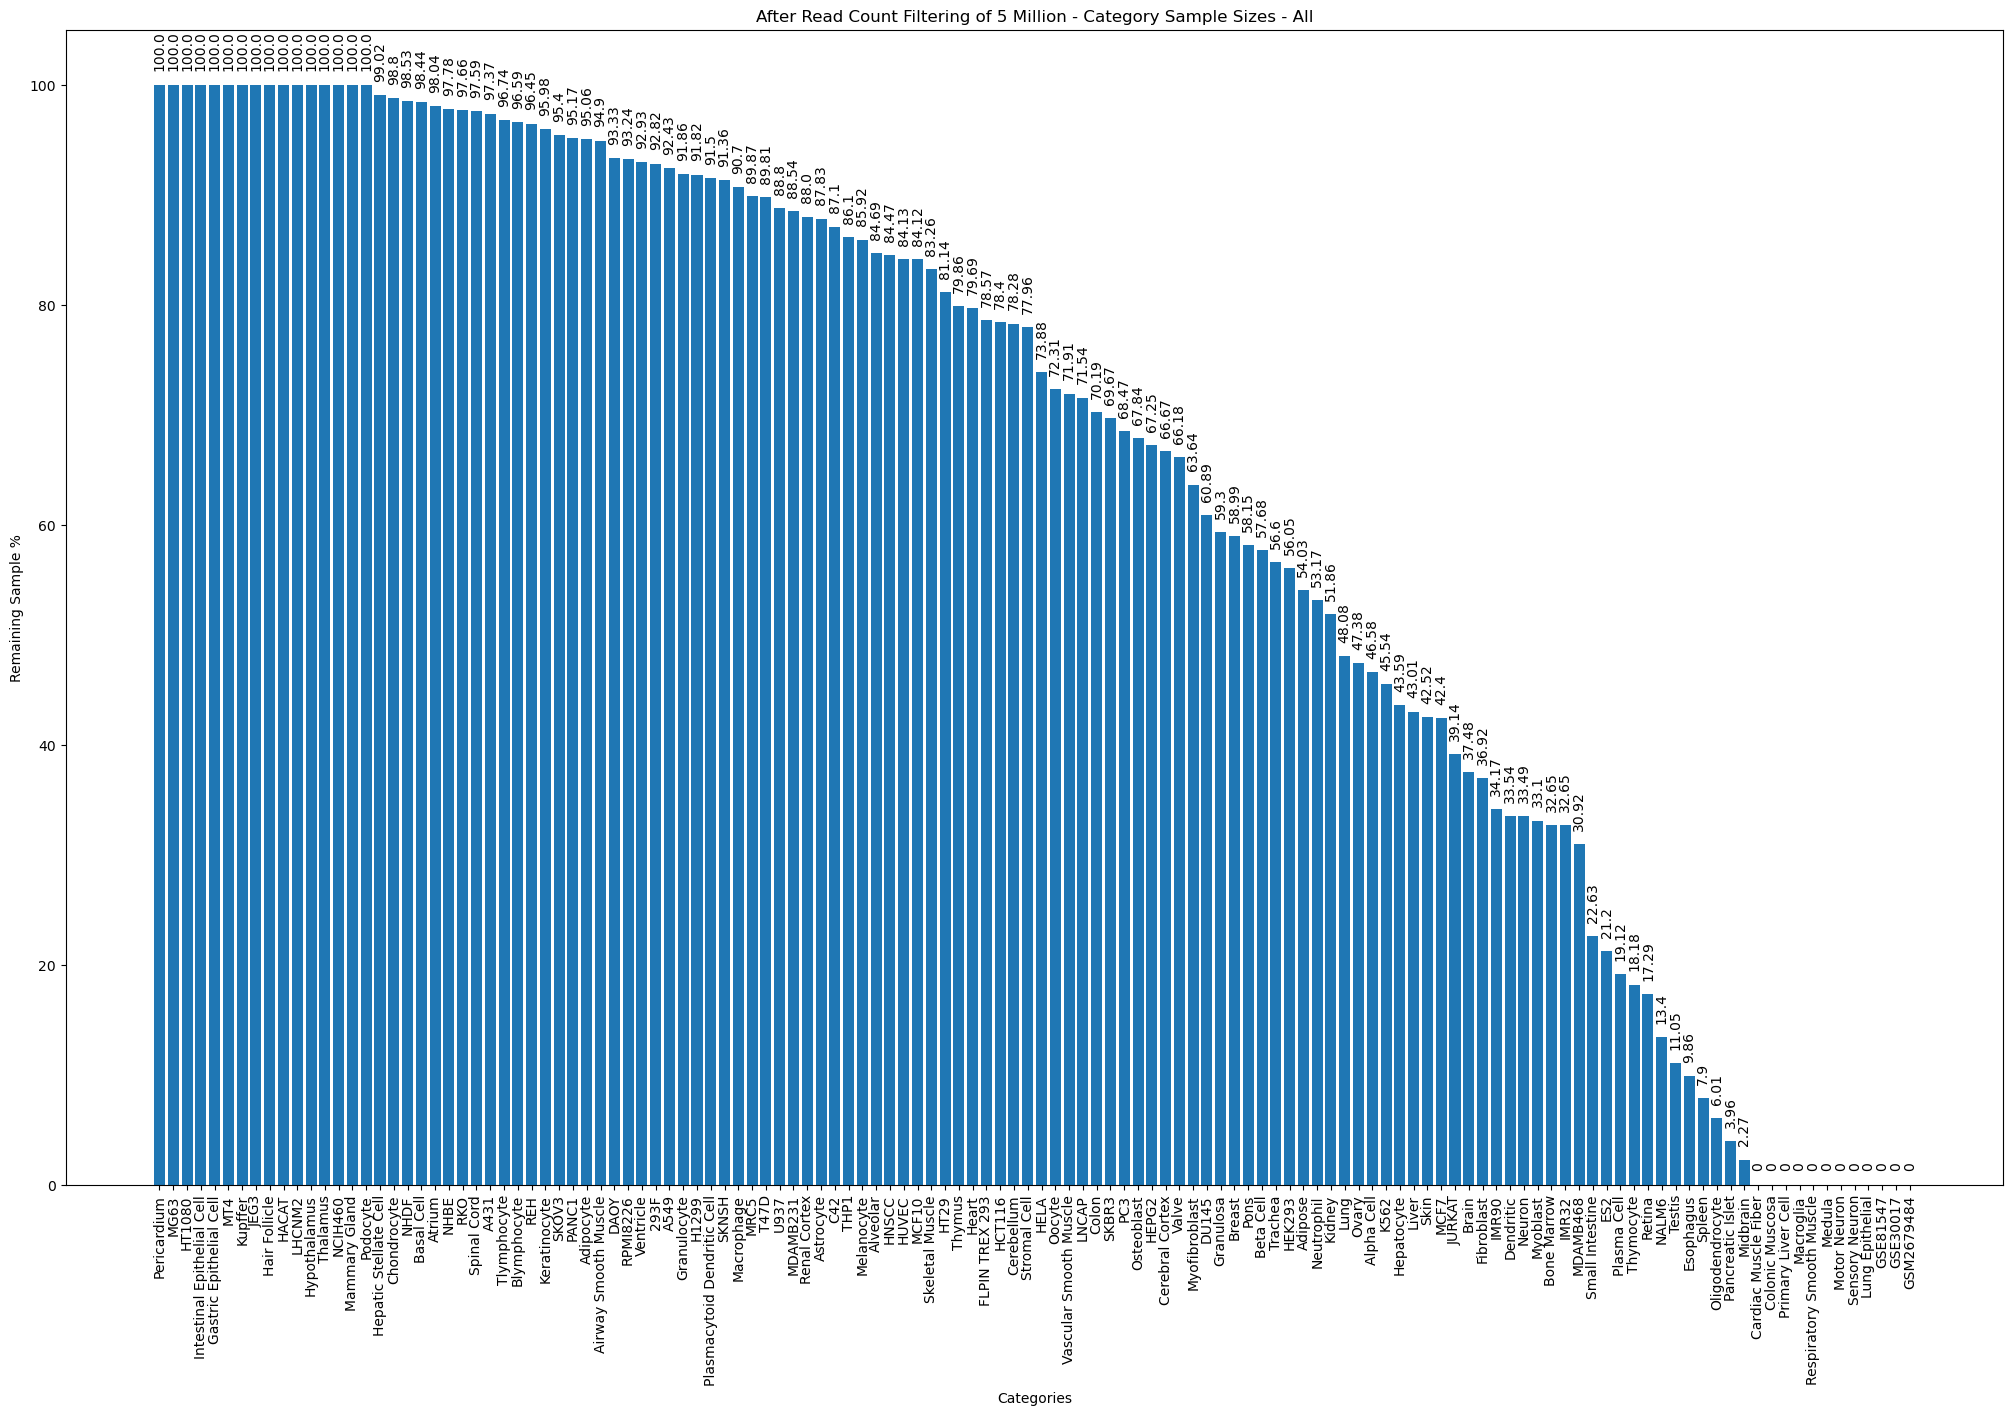

CPU times: user 2.07 s, sys: 408 ms, total: 2.48 s
Wall time: 2.38 s


In [6]:
%%time
import json
import matplotlib.pyplot as plt

# Load the data from the .json file
with open('/home/lwu/work/NarrativeGenomics/region_narration/code/pipeline/ARCHS4_LW/sbatch_files/results/category_uniqueSampleSizes_dict_LW20230121.json', 'r') as f:
    org_biosamples_dict = json.load(f)

# Print the value of the key 'key1'
#print(org_biosamples_dict['Heart'])

######
with open("filtered_category_uniqueSampleSizes_dict_LW20230123.json", "r") as f:
    filtered_sampleSize = json.load(f)

print("Data loaded******")
################################################################################################################
# Get the difference
import operator
sampleSize_diff = {}

for key in org_biosamples_dict:
    if key in filtered_sampleSize:
        if org_biosamples_dict[key] != 0:
            sampleSize_diff[key] = filtered_sampleSize[key]/org_biosamples_dict[key]
        else:
            sampleSize_diff[key] = 0
            
print("Plot Data Done. ******")

# sort the result dictionary in descending order based on the values
sorted_sampleSize_diff = dict(sorted(sampleSize_diff.items(), key=operator.itemgetter(1), reverse=True))

################################################################################################################
# get the keys and values from the sorted result dictionary
keys = list(sorted_sampleSize_diff.keys())
values = list(sorted_sampleSize_diff.values())

# convert to percentage
values = [v * 100 for v in values]

# get the keys and values from the sorted result dictionary
keys = list(sorted_sampleSize_diff.keys())
values = list(sorted_sampleSize_diff.values())

# convert to percentage
values = [v * 100 for v in values]

# Add the value labels
for i, v in enumerate(values):
    plt.annotate(str(round(v, 2)), xy=(i,v), xytext=(0,10), textcoords='offset points', ha='center', va='bottom', rotation = 90)

# create the bar plot
plt.bar(keys, values)
plt.xlabel('Categories')
plt.xticks(rotation=90)
fig = plt.gcf()
fig.set_size_inches(25, 15)
plt.ylabel('Remaining Sample %')
plt.title('After Read Count Filtering of 5 Million - Category Sample Sizes - All')
plt.show()

In [8]:
count = list(org_biosamples_dict.values()).count(0)
print(count)

12
